# Practice 3: Latent Space Classification

**Developed by:** Antonio Vila Leis and David Florez Mazuera

## Introduction

This project explores the use of unsupervised learning for feature extraction via an Autoencoder and subsequently leveraging those learned representations to train a classifier with limited labeled data.

The dataset used in this assignment is STL-10. It consists of 96x96 pixel color images belonging to 10 classes (such as airplanes, birds, cars, and cats). It provides a small subset of labeled images (5,000 for training, 800 per class for testing) alongside a huge pool of 100000 unlabeled images.

The project development is structured into five main phases:

1. **Setup and Preprocessing:** Loading the STL-10 dataset partitions (labeled and unlabeled) and applying appropriate preprocessing process.

2. **Baseline:** Evaluation of the performance obtained by a standard supervised CNN model (developed in Practice 1) trained solely on the labeled dataset. This establishes the benchmark to evaluate the effectiveness of the autoencoder-based approach.

3. **Unsupervised Training (Autoencoder):** Design and training of a Convolutional Autoencoder using the 100000 unlabeled images. The goal is to force the network to learn a compact and meaningful latent representation of the input space by learning to reconstruct the original images.

4. **Latent Space Classification:** Construction of a classifier on top of the frozen encoder trained in the previous step. The model will operate exclusively in the latent space, using the labeled images for training. This section also includes a thorough analysis of different regularization techniques to mitigate overfitting given the limited labeled data.

5. **Fine-Tuning:** An advanced refinement phase to explore techniques and parameters that allow for improvement of previous results.

## 1. Setup and Preprocessing

### Import Libraries and Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
    # Reduces the number of warnings
    
import tensorflow as tf
from tensorflow import keras
from keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds

# Configure matplotlib for inline plotting
%matplotlib inline

# Set random seeds for reproducibility
SEED = 123
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("="*60)
print("STL-10 Dataset CNN Classifier")
print("="*60)
print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")
print(f"GPU Available: {len(tf.config.list_physical_devices('GPU')) > 0}")
print("="*60)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
# To avoid stalling due to memory problems

STL-10 Dataset CNN Classifier
TensorFlow version: 2.16.2
Keras version: 3.12.0
GPU Available: True


### Configuration parameters

In [2]:
IMG_SIZE = 96  # STL-10 native size
UNS_BATCH_SIZE = 128
EPOCHS = 200
NUM_CLASSES = 10  # airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck
INITIAL_LR = 0.001

# Class names for visualization
CLASS_NAMES = ['airplane', 'bird', 'car', 'cat', 'deer', 
               'dog', 'horse', 'monkey', 'ship', 'truck']

print(f"Image Size: {IMG_SIZE}x{IMG_SIZE}")
print(f"Batch Size: {UNS_BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Number of Classes: {NUM_CLASSES}")
print(f"Initial Learning Rate: {INITIAL_LR}")
print(f"\nClasses: {', '.join(CLASS_NAMES)}")

Image Size: 96x96
Batch Size: 128
Epochs: 200
Number of Classes: 10
Initial Learning Rate: 0.001

Classes: airplane, bird, car, cat, deer, dog, horse, monkey, ship, truck


### Load STL-10 dataset

In [3]:
uns_raw, uns_info = tfds.load(
    "stl10",
    split="unlabelled",
    as_supervised=False,
    with_info=True,
    download=True
)

# Create training and validation splits from the unlabelled data
unlabelled_size = uns_info.splits['unlabelled'].num_examples
UNS_VAL_SIZE = int(unlabelled_size * 0.1)
UNS_TRAIN_SIZE = unlabelled_size - UNS_VAL_SIZE

def ae_preprocess(example):
    image = tf.cast(example["image"], tf.float32) / 255.0
    return image, image

uns_processed = (
    uns_raw
    .map(ae_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .ignore_errors()
    .cache()
)

uns_val = (
    uns_processed
    .take(UNS_VAL_SIZE)
    .batch(UNS_BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

uns_train = (
    uns_processed
    .skip(UNS_VAL_SIZE)
    .shuffle(1000, seed=SEED)
    .batch(UNS_BATCH_SIZE)
    .repeat()
    .prefetch(tf.data.AUTOTUNE)
)

/Users/davidflorezmazuera/Library/CloudStorage/SynologyDrive-dfm/Universidad/MIA/DL/dl_p3/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dl Completed...: 0 url [00:00, ? url/s]
Dl Completed...: 100%|██████████| 1/1 [00:00<00:00, 83.10 url/s] 
Extraction completed...: 0 file [00:00, ? file/s]
Dl Completed...: 100%|██████████| 1/1 [00:00<00:00, 66.09 url/s]


Dataset stl10 downloaded and prepared to /Users/davidflorezmazuera/tensorflow_datasets/stl10/1.0.0. Subsequent calls will reuse this data.


**Important:** When loading the models, using ``.repeat()`` helps prevent errors caused by corrupted samples. You must then specify the ``steps_per_epoch`` argument during training as shown below.

````
steps_per_epoch = unlabelled_size // BATCH_SIZE
autoencoder.fit(
    ds_unlabeled,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=None
)


In [4]:
ds_train_raw = tfds.load('stl10', split='train[:80%]', as_supervised=True, download=True)
ds_val_raw   = tfds.load('stl10', split='train[80%:]', as_supervised=True, download=True)
ds_test_raw  = tfds.load('stl10', split='test', as_supervised=True, download=True)

In [6]:
import matplotlib.pyplot as plt

def plot(history, only_loss=False):
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]
    epochs = range(1, len(loss) + 1)

    if not only_loss:
        accuracy = history.history["accuracy"]
        val_accuracy = history.history["val_accuracy"]

        plt.figure(figsize=(8, 5))
        plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
        plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
        plt.title("Training and validation accuracy")
        plt.xlabel("Epochs")
        plt.ylabel("Accuracy")
        plt.legend()
        plt.show()
        
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

### Preprocessing

A preprocessing pipeline has been applied with the following key steps:

* Label transformation (One-Hot Encoding and Normalization): Numerical labels are converted into a categorical format and normalized (TODO ver si encaja poner normalized aqui con la explicacion posterior). This way, the model is prevented from mistakenly assuming that a hierarchical order exists among the classes.

* Batching: Finally, the data is packed into groups of 32 elements. This optimizes resource consumption during training.

In [7]:
def prepare_labeled_data(image, label):
    image = tf.cast(image, tf.float32) / 255.0 
    label = tf.cast(label, tf.int32)
    label = tf.one_hot(label, depth=10)
    return image, label


ds_train = ds_train_raw.map(prepare_labeled_data).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)
ds_val = ds_val_raw.map(prepare_labeled_data).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)
ds_test = ds_test_raw.map(prepare_labeled_data).batch(
    32).cache().prefetch(tf.data.AUTOTUNE)

Shape images: (32, 96, 96, 3)
Shape labels: (32, 10)
Min/Max images: tf.Tensor(0.0, shape=(), dtype=float32) tf.Tensor(1.0, shape=(), dtype=float32)
Sample label: tf.Tensor([0. 1. 0. 0. 0. 0. 0. 0. 0. 0.], shape=(10,), dtype=float32)


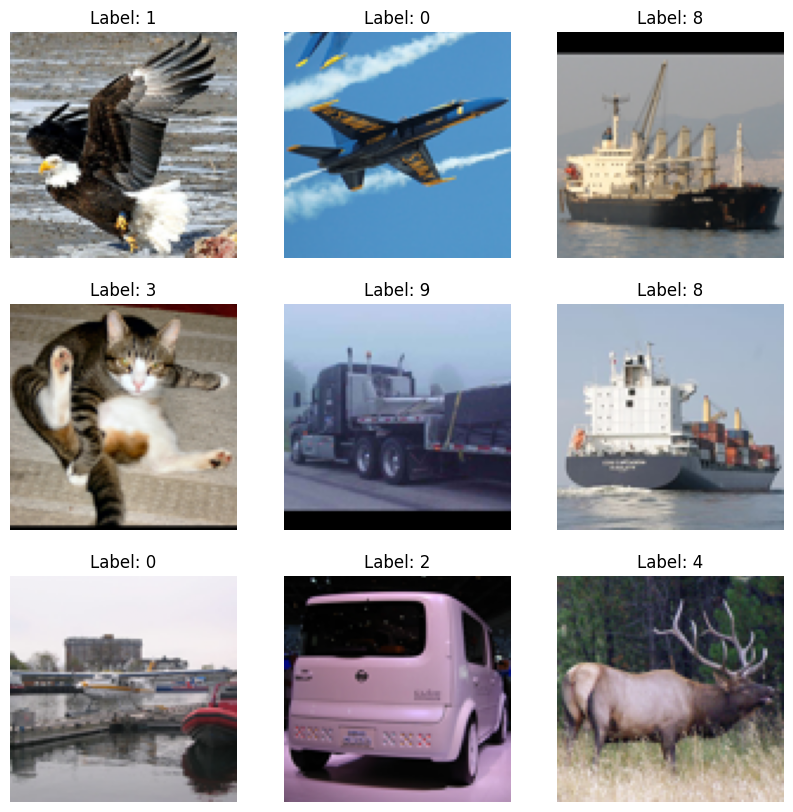

In [8]:
# Verify that the data is correct
import matplotlib.pyplot as plt

for images, labels in ds_train.take(1):
    print("Shape images:", images.shape)
    print("Shape labels:", labels.shape)
    print("Min/Max images:", tf.reduce_min(images), tf.reduce_max(images))
    print("Sample label:", labels[0])

# Visualize some images and their labels
for images, labels in ds_train.take(1):
    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(f"Label: {tf.argmax(labels[i])}")
        plt.axis('off')
    plt.show()

## 2. Baseline

In [53]:
def residual_block(x, filters, kernel_size=3, stride=1):
    shortcut = x

    # First layer of the block
    x = layers.SeparableConv2D(filters, kernel_size, strides=stride, padding='same')(x)
    x = layers.Activation('relu')(x)

    # Second layer of the block
    x = layers.SeparableConv2D(filters, kernel_size, padding='same')(x)

    # If shapes don't match (e.g., due to stride), adjust the shortcut
    if stride > 1 or shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, (1, 1), strides=stride, padding='same')(shortcut)

    x = layers.Add()([x, shortcut]) # The Residual Connection
    x = layers.Activation('relu')(x)
    return x

inputs = keras.Input(shape=(96, 96, 3))

# Data Augmentation
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1, fill_mode='reflect')(x)
x = layers.RandomZoom(0.1, fill_mode='reflect')(x)

# Entry Flow
x = layers.SeparableConv2D(32, (3, 3), padding='same')(x)
x = layers.Activation('relu')(x)

# Residual Stages (Increasing Depth)
x = residual_block(x, 64, stride=2)
x = residual_block(x, 64)

x = residual_block(x, 128, stride=2)
x = residual_block(x, 128)

x = residual_block(x, 256, stride=2)
x = residual_block(x, 256)

x = residual_block(x, 512, stride=2)
x = residual_block(x, 512)

# Classifier Head
x = layers.GlobalAveragePooling2D()(x) # Better than Flatten for deep nets
x = layers.Dropout(0.5)(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation='softmax')(x)

model_tuned = keras.Model(inputs=inputs, outputs=outputs)

model_tuned.compile(optimizer='adam',
                     loss='categorical_crossentropy',
                     metrics=['accuracy'])

model_tuned.summary()

Model: "functional_46"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip_1       │ (None, 96, 96, 3) │          0 │ input_layer_13[0… │
│ (RandomFlip)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation_1   │ (None, 96, 96, 3) │          0 │ random_flip_1[0]… │
│ (RandomRotation)    │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom_1       │ (None, 96, 96, 3) │          0 │ random_rotation_… │
│ (RandomZoom)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_17 │ (None, 96, 96,    │        155 │ random_zoom_1[0]… │
│ (SeparableConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_17       │ (None, 96, 96,    │          0 │ separable_conv2d… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_18 │ (None, 48, 48,    │      2,400 │ activation_17[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_18       │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_19 │ (None, 48, 48,    │      4,736 │ activation_18[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 48, 48,    │      2,112 │ activation_17[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (None, 48, 48,    │          0 │ separable_conv2d… │
│                     │ 64)               │            │ conv2d_13[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_19       │ (None, 48, 48,    │          0 │ add_8[0][0]       │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_20 │ (None, 48, 48,    │      4,736 │ activation_19[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_20       │ (None, 48, 48,    │          0 │ separable_conv2d… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ separable_conv2d_21 │ (None, 48, 48,    │      4,736 │ activation_20[0]… │
│ (SeparableConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (None, 48, 48,    │          0 │ separable_conv2d… │
│                     │ 64)               │            │ activation_19[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_21       │ (None, 48, 48,    │          0 │ add_9[0][0]     

 Total params: 1,561,733 (5.96 MB)

 Trainable params: 1,561,733 (5.96 MB)

 Non-trainable params: 0 (0.00 B)

In [54]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history_tuned = model_tuned.fit(ds_train, validation_data=ds_val,
                    epochs=100, callbacks=[early_stopping, reduce_lr])

model_tuned.save("experiments/baseline.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 20s 124ms/step - accuracy: 0.1482 - loss: 2.2286 - val_accuracy: 0.1800 - val_loss: 2.1480 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 121ms/step - accuracy: 0.1922 - loss: 2.0724 - val_accuracy: 0.1860 - val_loss: 2.0661 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 14s 115ms/step - accuracy: 0.2377 - loss: 1.9616 - val_accuracy: 0.2520 - val_loss: 1.8718 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.2603 - loss: 1.8608 - val_accuracy: 0.2730 - val_loss: 1.7974 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 135ms/step - accuracy: 0.2850 - loss: 1.8107 - val_accuracy: 0.2740 - val_loss: 1.8673 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 16s 124ms/step - accuracy: 0.2982 - loss: 1.7786 - val_accuracy: 0.2940 - val_loss: 1.7725 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 15s 118ms/step - accura

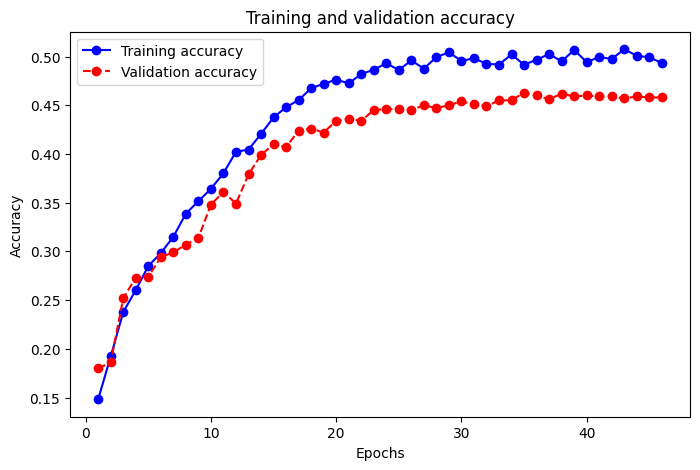

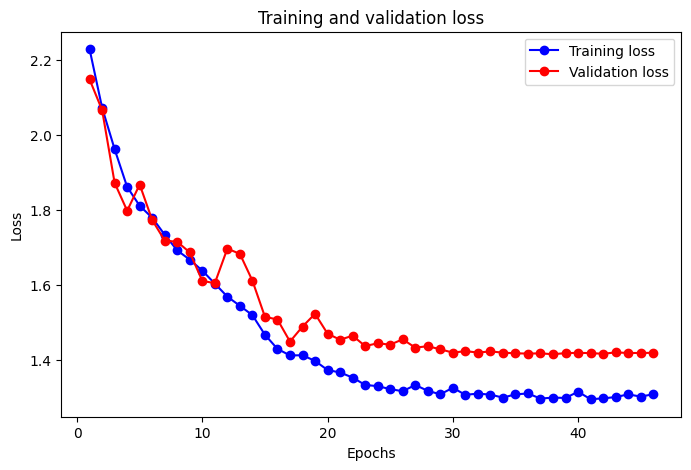

In [55]:
plot(history_tuned)

In [88]:
print("\n--- Test Evaluation ---")
test_loss, test_acc = model_tuned.evaluate(ds_test)
print(f"Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")


--- Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 31ms/step - accuracy: 0.4843 - loss: 1.3806
Test Accuracy: 0.4843 | Test Loss: 1.3806


## 3. Unsupervised Training (Autoencoder)

In [15]:
LATENT_DIM = 1024

encoder_input = layers.Input(shape=(96, 96, 3))
e1 = layers.Conv2D(32, 3, activation='relu', padding='same', strides=2)(encoder_input)
e2 = layers.Conv2D(64, 3, activation='relu', padding='same', strides=2)(e1)
e3 = layers.Conv2D(128, 3, activation='relu', padding='same', strides=2)(e2)
e4 = layers.Conv2D(256, 3, activation='relu', padding='same', strides=2)(e3)

latent = layers.Flatten()(e4)
latent = layers.Dense(LATENT_DIM, activation='relu')(latent)

encoder = models.Model(encoder_input, latent, name='encoder')
encoder.summary()

decoder_input = layers.Input(shape=(LATENT_DIM,))
d = layers.Dense(6 * 6 * 256, activation='relu')(decoder_input)
d = layers.Reshape((6, 6, 256))(d)
d = layers.Conv2DTranspose(128, 3, activation='relu', padding='same', strides=2)(d)
d = layers.Concatenate()([d, e3])
d = layers.Conv2DTranspose(64, 3, activation='relu', padding='same', strides=2)(d)
d = layers.Concatenate()([d, e2])
d = layers.Conv2DTranspose(32, 3, activation='relu', padding='same', strides=2)(d)
d = layers.Concatenate()([d, e1])
decoder_output = layers.Conv2DTranspose(3, 3, activation='sigmoid', padding='same', strides=2)(d)

decoder = models.Model(decoder_input, decoder_output, name='decoder')
decoder.summary()

outputs = decoder(encoder(encoder_input))
autoencoder = models.Model(encoder_input, outputs, name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')

autoencoder.summary()


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 48, 48, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1024)           │     9,438,208 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,826,624 (37.49 MB)

 Trainable params: 9,826,624 (37.49 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

... (5 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 1024)           │     9,826,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 96, 96, 3)      │    10,020,835 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,754,211 (75.36 MB)

 Trainable params: 19,754,211 (75.36 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
LATENT_DIM = 1024
encoder_input = layers.Input(shape=(96, 96, 3), name='encoder_input')
e1 = layers.Conv2D(32, 3, activation='relu', padding='same', strides=2, name='e1')(encoder_input)
e2 = layers.Conv2D(64, 3, activation='relu', padding='same', strides=2, name='e2')(e1)
e3 = layers.Conv2D(128, 3, activation='relu', padding='same', strides=2, name='e3')(e2)
e4 = layers.Conv2D(256, 3, activation='relu', padding='same', strides=2, name='e4')(e3)
latent = layers.Flatten(name='flatten')(e4)
latent = layers.Dense(LATENT_DIM, activation='relu', name='latent')(latent)
d = layers.Dense(6 * 6 * 256, activation='relu', name='d_dense')(latent)
d = layers.Reshape((6, 6, 256), name='d_reshape')(d)
d = layers.Conv2DTranspose(128, 3, activation='relu', padding='same', strides=2, name='d_conv1')(d)
d = layers.Concatenate(name='skip1')([d, e3])
d = layers.Conv2DTranspose(64, 3, activation='relu', padding='same', strides=2, name='d_conv2')(d)
d = layers.Concatenate(name='skip2')([d, e2])
d = layers.Conv2DTranspose(32, 3, activation='relu', padding='same', strides=2, name='d_conv3')(d)
d = layers.Concatenate(name='skip3')([d, e1])
decoder_output = layers.Conv2DTranspose(3, 3, activation='sigmoid', padding='same', strides=2, name='decoder_output')(d)
autoencoder = models.Model(encoder_input, decoder_output, name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 96, 96, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e1 (Conv2D)         │ (None, 48, 48,    │        896 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e2 (Conv2D)         │ (None, 24, 24,    │     18,496 │ e1[0][0]          │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e3 (Conv2D)         │ (None, 12, 12,    │     73,856 │ e2[0][0]          │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ e4 (Conv2D)         │ (None, 6, 6, 256) │    295,168 │ e3[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 9216)      │          0 │ e4[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ latent (Dense)      │ (None, 1024)      │  9,438,208 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_dense (Dense)     │ (None, 9216)      │  9,446,400 │ latent[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_reshape (Reshape) │ (None, 6, 6, 256) │          0 │ d_dense[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv1             │ (None, 12, 12,    │    295,040 │ d_reshape[0][0]   │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip1 (Concatenate) │ (None, 12, 12,    │          0 │ d_conv1[0][0],    │
│                     │ 256)              │            │ e3[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv2             │ (None, 24, 24,    │    147,520 │ skip1[0][0]       │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip2 (Concatenate) │ (None, 24, 24,    │          0 │ d_conv2[0][0],    │
│                     │ 128)              │            │ e2[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ d_conv3             │ (None, 48, 48,    │     36,896 │ skip2[0][0]       │
│ (Conv2DTranspose)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ skip3 (Concatenate) │ (None, 48, 48,    │          0 │ d_conv3[0][0],    │
│                     │ 64)               │            │ e1[0][0]          │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_output      │ (None, 96, 96, 3) │      1,731 │ skip3[0][0]       │
│ (Conv2DTranspose)   │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 19,754,211 (75.36 MB)

 Trainable params: 19,754,211 (75.36 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import keras
from tensorflow import expand_dims

steps_per_epoch = UNS_TRAIN_SIZE // UNS_BATCH_SIZE

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)

history_uns = autoencoder.fit(
    uns_train, 
    epochs=100, 
    steps_per_epoch=steps_per_epoch,
    validation_data=uns_val,
    callbacks=[early_stopping]
)

autoencoder.save("experiments/basic_autoencoder.keras")


Epoch 1/100
375/703 ━━━━━━━━━━━━━━━━━━━━ 1:08 210ms/step - loss: 0.0263

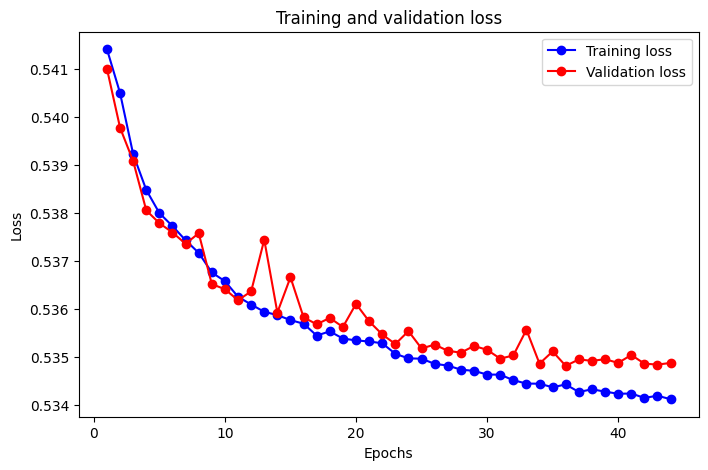

In [ ]:
plot(history_uns, only_loss=True)

## 4. Latent Space Classification

In [80]:
import keras
from keras import layers, models

# Get the pretrained encoder
autoencoder = keras.models.load_model("experiments/basic_autoencoder.keras")
pretrained_encoder = autoencoder.layers[0] 
pretrained_encoder.trainable = False 

# Build the new classifier
inputs = layers.Input(shape=(96, 96, 3))
x = pretrained_encoder(inputs)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(10, activation='softmax')(x)
classifier = models.Model(inputs=inputs, outputs=outputs, name="latent_classifier")

classifier.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

classifier.summary()

Model: "latent_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_16 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_6 (Sequential)       │ (None, 256)            │     4,812,096 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,880,458 (18.62 MB)

 Trainable params: 68,362 (267.04 KB)

 Non-trainable params: 4,812,096 (18.36 MB)

In [81]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", mode="min", patience=8, restore_best_weights=True)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss", factor=0.3, patience=3, min_lr=1e-7, verbose=1)

history_classifier = classifier.fit(ds_train, validation_data=ds_val,
                    epochs=100, callbacks=[early_stopping, reduce_lr])

classifier.save("experiments/latent_classifier.keras")

Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1815 - loss: 2.4468 - val_accuracy: 0.2670 - val_loss: 2.0227 - learning_rate: 0.0010
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2410 - loss: 2.0106 - val_accuracy: 0.2580 - val_loss: 1.9109 - learning_rate: 0.0010
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2618 - loss: 1.9360 - val_accuracy: 0.2840 - val_loss: 1.8532 - learning_rate: 0.0010
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2890 - loss: 1.8641 - val_accuracy: 0.2860 - val_loss: 1.8232 - learning_rate: 0.0010
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.2935 - loss: 1.8480 - val_accuracy: 0.3180 - val_loss: 1.7899 - learning_rate: 0.0010
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3212 - loss: 1.8077 - val_accuracy: 0.3260 - val_loss: 1.7596 - learning_rate: 0.0010
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3203 - loss: 1.

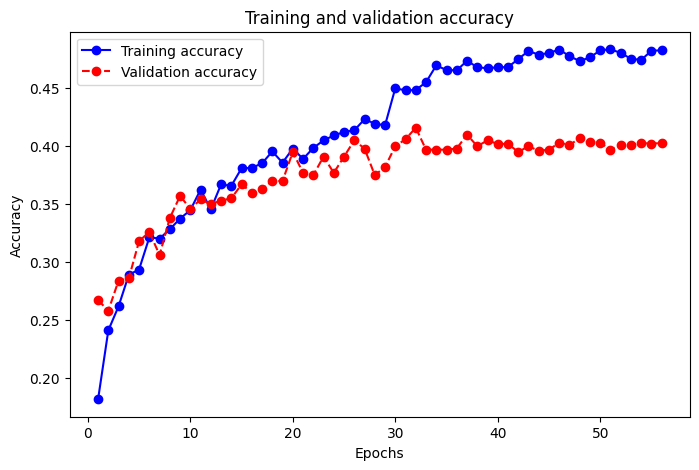

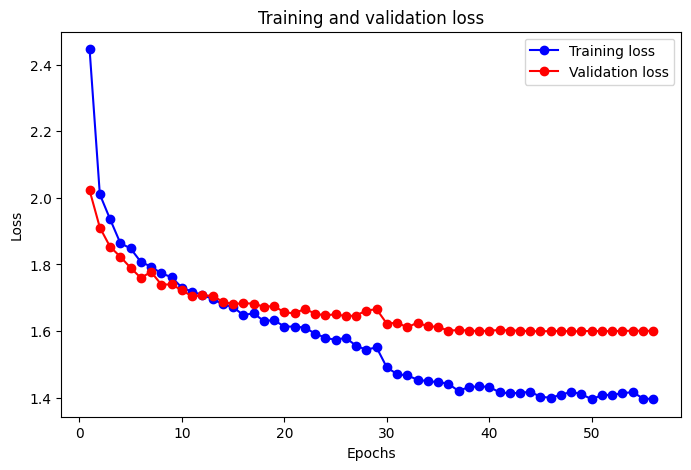

In [82]:
plot(history_classifier)

In [85]:
print("\n--- Test Evaluation ---")
test_loss, test_acc = classifier.evaluate(ds_test)
print(f"Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")


--- Test Evaluation ---
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.4168 - loss: 1.5996
Test Accuracy: 0.4168 | Test Loss: 1.5996


## 5. Fine-Tuning

In [ ]:
# TODO